<a href="https://colab.research.google.com/github/Akshat1686/ML-MINI-Project/blob/main/book_review_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from pathlib import Path

for name in [
    "goodreads_reviews_dedup.json.gz",
    "goodreads_books.json.gz",
    "filtered_reviews.csv"
]:
    matches = list(Path("/content").rglob(name))
    if matches:
        for p in matches:
            print(f"FOUND: {p} | {p.stat().st_size / (1024**3):.2f} GB")
    else:
        print(f"MISSING: {name}")

MISSING: goodreads_reviews_dedup.json.gz
MISSING: goodreads_books.json.gz
MISSING: filtered_reviews.csv


In [4]:
import subprocess
from pathlib import Path

files = {
    "goodreads_reviews_dedup.json.gz":
        "https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/goodreads_reviews_dedup.json.gz",
    "goodreads_books.json.gz":
        "https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/goodreads_books.json.gz",
}

for filename, url in files.items():
    path = Path("/content") / filename
    if not path.exists() or path.stat().st_size == 0:
        print(f"Downloading {filename}...")
        subprocess.run(["wget", "-c", url, "-O", str(path)], check=True)
    print(f"Ready: {path} ({path.stat().st_size / (1024**3):.2f} GB)")

print("Both downloads are complete.")

Ready: /content/goodreads_reviews_dedup.json.gz (4.98 GB)
Ready: /content/goodreads_books.json.gz (1.94 GB)
Both downloads are complete.


In [1]:
from pathlib import Path

for p in Path("/content").rglob("filtered_reviews.csv"):
    print("FOUND:", p, f"| Size: {p.stat().st_size / (1024**2):.1f} MB")

In [5]:
from pathlib import Path
import subprocess

reviews_path = Path("/content/goodreads_reviews_dedup.json.gz")

if not reviews_path.exists() or reviews_path.stat().st_size == 0:
    subprocess.run([
        "wget", "-c",
        "https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/goodreads_reviews_dedup.json.gz",
        "-O", str(reviews_path)
    ], check=True)

print("Reviews file ready:", reviews_path.exists())
print(f"Size: {reviews_path.stat().st_size / (1024**3):.2f} GB")

Reviews file ready: True
Size: 4.98 GB


from pathlib import Path

print("Files available:")
for p in Path("/content").glob("*"):
    print(p.name)

In [7]:
import gzip
import json

books_path = "/content/goodreads_books.json.gz"

with gzip.open(books_path, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        book = json.loads(line)
        print("Available book fields:", list(book.keys()))
        print("\nExample values:")
        for key in list(book.keys())[:10]:
            print(f"{key}: {str(book[key])[:150]}")
        break

Available book fields: ['isbn', 'text_reviews_count', 'series', 'country_code', 'language_code', 'popular_shelves', 'asin', 'is_ebook', 'average_rating', 'kindle_asin', 'similar_books', 'description', 'format', 'link', 'authors', 'publisher', 'num_pages', 'publication_day', 'isbn13', 'publication_month', 'edition_information', 'publication_year', 'url', 'image_url', 'book_id', 'ratings_count', 'work_id', 'title', 'title_without_series']

Example values:
isbn: 0312853122
text_reviews_count: 1
series: []
country_code: US
language_code: 
popular_shelves: [{'count': '3', 'name': 'to-read'}, {'count': '1', 'name': 'p'}, {'count': '1', 'name': 'collection'}, {'count': '1', 'name': 'w-c-fields'}, {'count':
asin: 
is_ebook: false
average_rating: 4.00
kindle_asin: 


In [10]:
import pandas as pd

books = pd.read_json(
    "/content/goodreads_books.json.gz",
    lines=True,
    compression="gzip",
    nrows=5
)

print(books[["book_id", "title", "ratings_count", "average_rating"]])

   book_id                                              title  ratings_count  \
0  5333265                        W.C. Fields: A Life on Film              3   
1  1333909                                        Good Harbor             10   
2  7327624  The Unschooled Wizard (Sun Wolf and Starhawk, ...            140   
3  6066819                               Best Friends Forever          51184   
4   287140  Runic Astrology: Starcraft and Timekeeping in ...             15   

   average_rating  
0            4.00  
1            3.23  
2            4.03  
3            3.49  
4            3.40  


In [9]:
from pathlib import Path

for p in Path("/content").rglob("*.ipynb"):
    print(p)

In [11]:
import requests

url = "https://api.github.com/repos/Akshat1686/ML-MINI-Project/contents"
response = requests.get(url, timeout=15)

print("Status:", response.status_code)
if response.ok:
    for item in response.json():
        print(item["type"], item["name"])
else:
    print(response.text[:500])

Status: 200
dir Notebooks


In [12]:
import requests

url = "https://api.github.com/repos/Akshat1686/ML-MINI-Project/contents/Notebooks"
response = requests.get(url, timeout=15)
response.raise_for_status()

for item in response.json():
    print(item["name"], "—", item["download_url"])

book_review_validation.ipynb — https://raw.githubusercontent.com/Akshat1686/ML-MINI-Project/main/Notebooks/book_review_validation.ipynb
goodreads_preprocessing.ipynb — https://raw.githubusercontent.com/Akshat1686/ML-MINI-Project/main/Notebooks/goodreads_preprocessing.ipynb


In [13]:
import requests
import nbformat

base = "https://raw.githubusercontent.com/Akshat1686/ML-MINI-Project/main/Notebooks/"

for filename in ["goodreads_preprocessing.ipynb", "book_review_validation.ipynb"]:
    response = requests.get(base + filename, timeout=20)
    response.raise_for_status()
    notebook = nbformat.reads(response.text, as_version=4)

    print(f"\n{'='*20} {filename} {'='*20}")
    for i, cell in enumerate(notebook.cells):
        if cell.cell_type == "code":
            code = cell.source
            if any(word in code.lower() for word in [
                "popular", "threshold", "filtered_reviews",
                "ratings_count", "label", "target"
            ]):
                print(f"\n--- Cell {i+1} ---\n{code[:1800]}")


==================== goodreads_preprocessing.ipynb ====================

--- Cell 9 ---
from pathlib import Path
import sqlite3, time, urllib.request
import numpy as np
import pandas as pd

REVIEWS_PATH = Path("/content/goodreads_reviews_dedup.json.gz")
BOOKS_PATH = Path("/content/goodreads_books.json.gz")  # or .json
WORK_DIR = Path("/content/goodreads_preprocessing")
WORK_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK_DIR / "goodreads_stats.sqlite"
OUTPUT_CSV = WORK_DIR / "filtered_reviews.csv"
FASTTEXT_MODEL_PATH = WORK_DIR / "lid.176.bin"

# Lower these if RAM is tight.
REVIEW_CHUNK_SIZE = 5_000
BOOK_CHUNK_SIZE = 10_000
LANGUAGE_BATCH_SIZE = 500

REPLICATION_MODE = "repository"  # set to "paper" for paper threshold 0.025
POPULAR_THRESHOLD = 0.02 if REPLICATION_MODE == "repository" else 0.025
ENGLISH_PROBABILITY_THRESHOLD = 0.90

print("Review file:", REVIEWS_PATH)
print("Book file:", BOOKS_PATH)
print("Mode / popularity threshold:", REPLICATION_MODE, POPULAR_THRESHOLD)
prin

In [14]:
from pathlib import Path

for name in [
    "goodreads_reviews_dedup.json.gz",
    "goodreads_books.json.gz",
    "goodreads_preprocessing/filtered_reviews.csv"
]:
    p = Path("/content") / name
    print(f"{name}: {'READY' if p.exists() else 'MISSING'}")

goodreads_reviews_dedup.json.gz: READY
goodreads_books.json.gz: READY
goodreads_preprocessing/filtered_reviews.csv: MISSING


In [15]:
import requests
import nbformat

url = "https://raw.githubusercontent.com/Akshat1686/ML-MINI-Project/main/Notebooks/goodreads_preprocessing.ipynb"
response = requests.get(url, timeout=30)
response.raise_for_status()
nb = nbformat.reads(response.text, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code" and any(
        term in cell.source
        for term in ["POPULAR_THRESHOLD", "like_share", '"popular"', "'popular'"]
    ):
        print(f"\n--- CELL {i + 1} ---")
        print(cell.source[:3500])



--- CELL 9 ---
from pathlib import Path
import sqlite3, time, urllib.request
import numpy as np
import pandas as pd

REVIEWS_PATH = Path("/content/goodreads_reviews_dedup.json.gz")
BOOKS_PATH = Path("/content/goodreads_books.json.gz")  # or .json
WORK_DIR = Path("/content/goodreads_preprocessing")
WORK_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK_DIR / "goodreads_stats.sqlite"
OUTPUT_CSV = WORK_DIR / "filtered_reviews.csv"
FASTTEXT_MODEL_PATH = WORK_DIR / "lid.176.bin"

# Lower these if RAM is tight.
REVIEW_CHUNK_SIZE = 5_000
BOOK_CHUNK_SIZE = 10_000
LANGUAGE_BATCH_SIZE = 500

REPLICATION_MODE = "repository"  # set to "paper" for paper threshold 0.025
POPULAR_THRESHOLD = 0.02 if REPLICATION_MODE == "repository" else 0.025
ENGLISH_PROBABILITY_THRESHOLD = 0.90

print("Review file:", REVIEWS_PATH)
print("Book file:", BOOKS_PATH)
print("Mode / popularity threshold:", REPLICATION_MODE, POPULAR_THRESHOLD)
print("Output:", OUTPUT_CSV)

--- CELL 23 ---

import gzip
import json
import

In [17]:
for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code" and "popular" in cell.source and i == 22:
        source = cell.source
        for term in ["like_share", "POPULAR_THRESHOLD", '"popular"']:
            pos = source.find(term)
            if pos >= 0:
                print(f"\n--- Logic around {term} ---")
                print(source[max(0, pos - 500):pos + 1000])



--- Logic around like_share ---
 time
import sqlite3
import numpy as np
import pandas as pd
from pathlib import Path

# Assumes these already exist from earlier cells:
# REVIEWS_PATH, OUTPUT_CSV, DB_PATH, qualifying_books,
# max_review_date, language_model, POPULAR_THRESHOLD

CHECKPOINT_PATH = OUTPUT_CSV.with_suffix(".checkpoint.json")
BATCH_SIZE = 500
LOG_EVERY = 50_000

OUTPUT_COLUMNS = [
    "book_id", "user_reviews", "user_rating", "avg_rating",
    "ratings_count", "review_text", "days_since_review",
    "review_likes", "like_share", "popular"
]

def open_review_file(path):
    if str(path).endswith(".gz"):
        return gzip.open(path, "rt", encoding="utf-8")
    return open(path, "rt", encoding="utf-8")

def as_number(value, default=0):
    try:
        result = float(value)
        return result if np.isfinite(result) else default
    except (TypeError, ValueError):
        return default

def parse_date(value):
    if not value:
        return pd.NaT
    return pd.to_datetim

In [18]:
source = nb.cells[22].source
lines = source.splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "like_share", "popular_threshold", "popular =", '"popular":',
        "'popular':", "review_likes"
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 5)
        print(f"\n--- Lines {start + 1}-{end} ---")
        print("\n".join(f"{j+1}: {lines[j]}" for j in range(start, end)))



--- Lines 9-16 ---
9: 
10: # Assumes these already exist from earlier cells:
11: # REVIEWS_PATH, OUTPUT_CSV, DB_PATH, qualifying_books,
12: # max_review_date, language_model, POPULAR_THRESHOLD
13: 
14: CHECKPOINT_PATH = OUTPUT_CSV.with_suffix(".checkpoint.json")
15: BATCH_SIZE = 500
16: LOG_EVERY = 50_000

--- Lines 18-25 ---
18: OUTPUT_COLUMNS = [
19:     "book_id", "user_reviews", "user_rating", "avg_rating",
20:     "ratings_count", "review_text", "days_since_review",
21:     "review_likes", "like_share", "popular"
22: ]
23: 
24: def open_review_file(path):
25:     if str(path).endswith(".gz"):

--- Lines 151-158 ---
151:             "user_rating": entry.get("rating"),
152:             "review_text": text,
153:             "review_date": review_date,
154:             "review_likes": engagement
155:         })
156:         eligible_seen += 1
157:         last_saved_line = line_no
158: 

--- Lines 174-181 ---
174:             )
175:             batch_df["user_reviews"] = batch_df["us

In [19]:

import gzip
import json
import pandas as pd
from pathlib import Path

reviews_path = Path("/content/goodreads_reviews_dedup.json.gz")

rows = []
limit = 50000

with gzip.open(reviews_path, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i >= limit:
            break
        try:
            item = json.loads(line)
            text = item.get("review_text", "")
            if text and len(text.strip()) >= 20:
                rows.append({
                    "review_text": text,
                    "user_rating": item.get("rating"),
                    "review_likes": item.get("n_votes", 0),
                    "popular": None
                })
        except (json.JSONDecodeError, TypeError):
            continue

sample_df = pd.DataFrame(rows)
print("Sample rows:", len(sample_df))
print("Columns:", sample_df.columns.tolist())
display(sample_df.head())


Sample rows: 48441
Columns: ['review_text', 'user_rating', 'review_likes', 'popular']


,review_text,user_rating,review_likes,popular
0,Mind blowingly cool. Best science fiction I've...,5,16,None
1,This is a special book. It started slow for ab...,5,28,None
2,I haven't read a fun mystery book in a while a...,3,6,None
3,"Fun, fast paced, and disturbing tale of murder...",4,22,None
4,A fun book that gives you a sense of living in...,4,8,None


In [20]:

from pathlib import Path

paths = [
    Path("/content/goodreads_preprocessing"),
    Path("/content/goodreads_preprocessing/goodreads_stats.sqlite"),
    Path("/content/goodreads_preprocessing/filtered_reviews.csv"),
    Path("/content/filtered_reviews.csv"),
]

for p in paths:
    if p.is_dir():
        print(f"\n{p}/")
        for child in p.iterdir():
            print(f"  {child.name} — {child.stat().st_size / (1024**2):.1f} MB")
    else:
        print(f"{p}: {'EXISTS' if p.exists() else 'MISSING'}")


/content/goodreads_preprocessing: MISSING
/content/goodreads_preprocessing/goodreads_stats.sqlite: MISSING
/content/goodreads_preprocessing/filtered_reviews.csv: MISSING
/content/filtered_reviews.csv: MISSING


Rows: 48441
Baseline target counts:
popular
0    47505
1      936
Name: count, dtype: int64

Accuracy: 0.9494

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      9502
           1       0.19      0.51      0.28       187

    accuracy                           0.95      9689
   macro avg       0.59      0.73      0.63      9689
weighted avg       0.97      0.95      0.96      9689



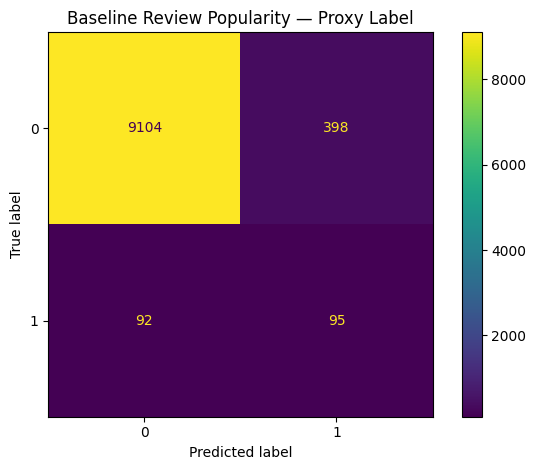

In [21]:

# Baseline model — uses the sample already loaded in sample_df
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay
)

df = sample_df.copy()
df["review_likes"] = pd.to_numeric(df["review_likes"], errors="coerce")
df = df.dropna(subset=["review_text", "review_likes"])
df = df[df["review_text"].str.strip().ne("")].copy()

# Temporary baseline label, NOT the project's official target
df["popular"] = (df["review_likes"] >= 10).astype(int)

print("Rows:", len(df))
print("Baseline target counts:")
print(df["popular"].value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    df["review_text"], df["popular"],
    test_size=0.2, random_state=42, stratify=df["popular"]
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000, stop_words="english",
        ngram_range=(1, 2), min_df=2, max_df=0.95
    )),
    ("classifier", LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, pred), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.title("Baseline Review Popularity — Proxy Label")
plt.tight_layout()
plt.show()


In [22]:

import pickle
import json
from pathlib import Path
from sklearn.metrics import classification_report, accuracy_score

output_dir = Path("/content/model_training_outputs")
output_dir.mkdir(exist_ok=True)

# Save trained pipeline
with open(output_dir / "review_popularity_model.pkl", "wb") as f:
    pickle.dump(model, f)

# Save evaluation metrics
report = classification_report(
    y_test, pred, output_dict=True, zero_division=0
)

results = {
    "target_definition": "Temporary proxy: popular if review_likes >= 10",
    "official_target_implemented": False,
    "accuracy": float(accuracy_score(y_test, pred)),
    "classification_report": report,
    "dataset_rows": int(len(df)),
    "random_state": 42
}

with open(output_dir / "evaluation_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved files:")
for p in output_dir.iterdir():
    print(p.name, f"({p.stat().st_size / 1024:.1f} KB)")


Saved files:
review_popularity_model.pkl (906.5 KB)
evaluation_results.json (0.9 KB)
